In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/dinooxylenght/dinozor_verisi_tam_database.csv


In [2]:
df = pd.read_csv(
    "/kaggle/input/dinooxylenght/dinozor_verisi_tam_database.csv",
    header=None,
    engine="python"
)

df.head()

,0,1,2,3,4,5,6,7,8
0,dinosaur_name,early_interval,late_interval,early_age_mya,country_code,continent,length,era,oxygenLevel
1,Rebbachisauridae indet.,Barremian,Early Aptian,125.77,AR,South America,13.0,Mesozoic,23.0
2,? Theropoda indet.,Late Barremian,NaN,125.77,TH,Asia,5.0,Mesozoic,23.0
3,Theropoda indet.,Early Cenomanian,Middle Cenomanian,100.5,AU,Australia,5.0,Mesozoic,23.0
4,cf. Bonapartenykus ultimus,Late Campanian,Early Maastrichtian,83.6,AR,South America,3.0,Mesozoic,23.0


In [3]:
# Sütunları indekslerine göre seçiyoruz (0'dan 6'ya kadar toplam 7 sütun)
df_clean = df[[0, 1, 2, 3, 4, 5, 6, 7, 8]]

# Sütun isimlerini atıyoruz (Virgüllere dikkat!)
df_clean.columns = [
    "dinosaur_name",
    "early_interval",
    "late_interval",
    "early_age_mya",
    "country_code",
    "continent",
    "length",
    "Geolocic_time",
    "oxy_Level"
]

# İsim kısmı boş olan satırları temizliyoruz
df_clean = df_clean.dropna(subset=["dinosaur_name"])

# Sonucu kontrol ediyoruz
print("Tablonun Boyutu:", df_clean.shape)
df_clean.head()


Tablonun Boyutu: (809, 9)


,dinosaur_name,early_interval,late_interval,early_age_mya,country_code,continent,length,Geolocic_time,oxy_Level
0,dinosaur_name,early_interval,late_interval,early_age_mya,country_code,continent,length,era,oxygenLevel
1,Rebbachisauridae indet.,Barremian,Early Aptian,125.77,AR,South America,13.0,Mesozoic,23.0
2,? Theropoda indet.,Late Barremian,NaN,125.77,TH,Asia,5.0,Mesozoic,23.0
3,Theropoda indet.,Early Cenomanian,Middle Cenomanian,100.5,AU,Australia,5.0,Mesozoic,23.0
4,cf. Bonapartenykus ultimus,Late Campanian,Early Maastrichtian,83.6,AR,South America,3.0,Mesozoic,23.0


In [4]:
df_clean["continent"].value_counts()

continent
North America    404
Asia             205
South America     89
Australia         61
Europe            47
Africa             2
continent          1
Name: count, dtype: int64

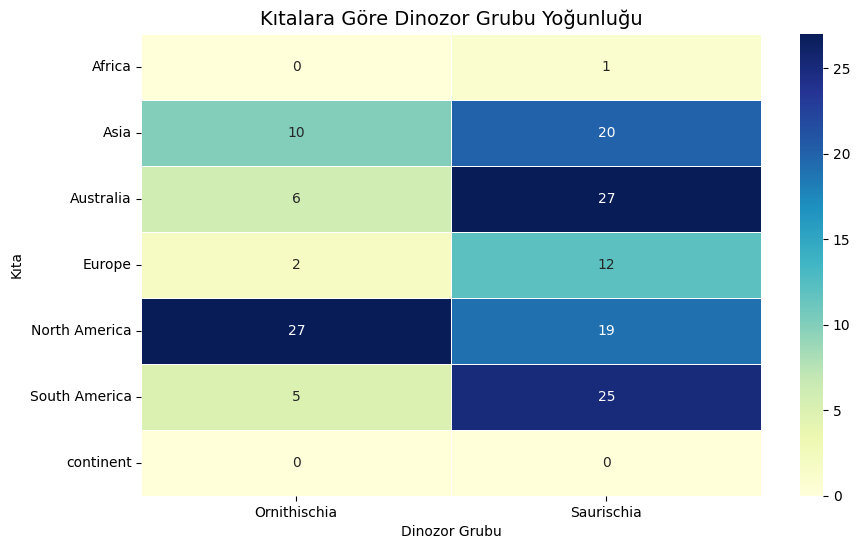

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- ADIM 1: dino_group Sütununu Oluşturma ---
# Dinosaur_name içindeki kelimelere göre basit bir gruplandırma yapalım
def classify_dino(name):
    name = str(name).lower()
    # Saurischia (Kertenkele kalçalılar: Etçiller ve Uzun boyunlular)
    if any(x in name for x in ['theropod', 'sauropod', 'titan', 'tyran', 'spino', 'raptor']):
        return 'Saurischia'
    # Ornithischia (Kuş kalçalılar: Boynuzlu, Zırhlı ve Ördek gagalılar)
    elif any(x in name for x in ['ornitho', 'hadrosaur', 'ceratops', 'ankylo', 'stego', 'pachy']):
        return 'Ornithischia'
    else:
        return 'Diğer'

# Yeni sütunu ekliyoruz
df_clean['dino_group'] = df_clean['dinosaur_name'].apply(classify_dino)

# --- ADIM 2: Çapraz Tablo (Pivot) ---
# df_clean kullandığından emin oluyoruz
heatmap_data = pd.crosstab(df_clean['continent'], df_clean['dino_group'])

# "Diğer" grubunu temizleyelim (grafik daha temiz olsun)
if 'Diğer' in heatmap_data.columns:
    heatmap_data = heatmap_data.drop(columns=['Diğer'])

# --- ADIM 3: Grafiği Çizelim ---
plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlGnBu", linewidths=.5)

plt.title('Kıtalara Göre Dinozor Grubu Yoğunluğu', fontsize=14)
plt.ylabel('Kıta')
plt.xlabel('Dinozor Grubu')
plt.show()

In [6]:
import pandas as pd
import os
from IPython.display import display

# --- DOSYA BULUCU ---
dosya_adi = 'dinozor_verisi_tam_database.csv'
dosya_yolu = ""
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file == dosya_adi:
            dosya_yolu = os.path.join(root, file)
            break
if dosya_yolu == "" and os.path.exists(dosya_adi): dosya_yolu = dosya_adi

# --- ANALİZ VE RENKLİ TABLO ---
if dosya_yolu:
    df = pd.read_csv(dosya_yolu)
    df['length'] = pd.to_numeric(df['length'], errors='coerce')
    df['oxygenLevel'] = pd.to_numeric(df['oxygenLevel'], errors='coerce')
    df['early_age_mya'] = pd.to_numeric(df['early_age_mya'], errors='coerce')

    # Dönem Belirleme Fonksiyonu
    def donem_adlandir(yas):
        if yas <= 145: return 'Kretase (Cretaceous)'
        if yas <= 201.3: return 'Jura (Jurassic)'
        if yas <= 252: return 'Trias (Triassic)'
        return 'Diger'

    df['Donem'] = df['early_age_mya'].apply(donem_adlandir)
    mezo_df = df[df['era'] == 'Mesozoic'].dropna(subset=['length', 'oxygenLevel'])

    # Gruplama: Dönem ve Oksijen beraber
    ozet = mezo_df.groupby(['Donem', 'oxygenLevel']).agg({
        'length': ['count', 'mean', 'max']
    }).reset_index()
    
    ozet.columns = ['Jeolojik Dönem', 'Oksijen (%)', 'Fosil Sayısı', 'Ortalama Boy (m)', 'Maksimum Boy (m)']

    print("📊 BİLİMSEL ANALİZ ÖZETİ (DÖNEM VE OKSİJEN)")
    
    # Görselleştirme: Maksimum boya göre renklendirme
    styled_table = ozet.style.background_gradient(subset=['Maksimum Boy (m)'], cmap='YlOrRd') \
                             .bar(subset=['Fosil Sayısı'], color='#5f9ad6') \
                             .format({'Ortalama Boy (m)': '{:.2f}'}) \
                             .set_properties(**{'text-align': 'center'})
    display(styled_table)
else:
    print("❌ Dosya bulunamadı!")

📊 BİLİMSEL ANALİZ ÖZETİ (DÖNEM VE OKSİJEN)


,Jeolojik Dönem,Oksijen (%),Fosil Sayısı,Ortalama Boy (m),Maksimum Boy (m)
0,Jura (Jurassic),18.000000,70,10.75,25.000000
1,Kretase (Cretaceous),23.000000,452,6.68,26.000000
2,Trias (Triassic),15.000000,9,3.63,6.500000
3,Trias (Triassic),18.000000,4,6.03,12.000000


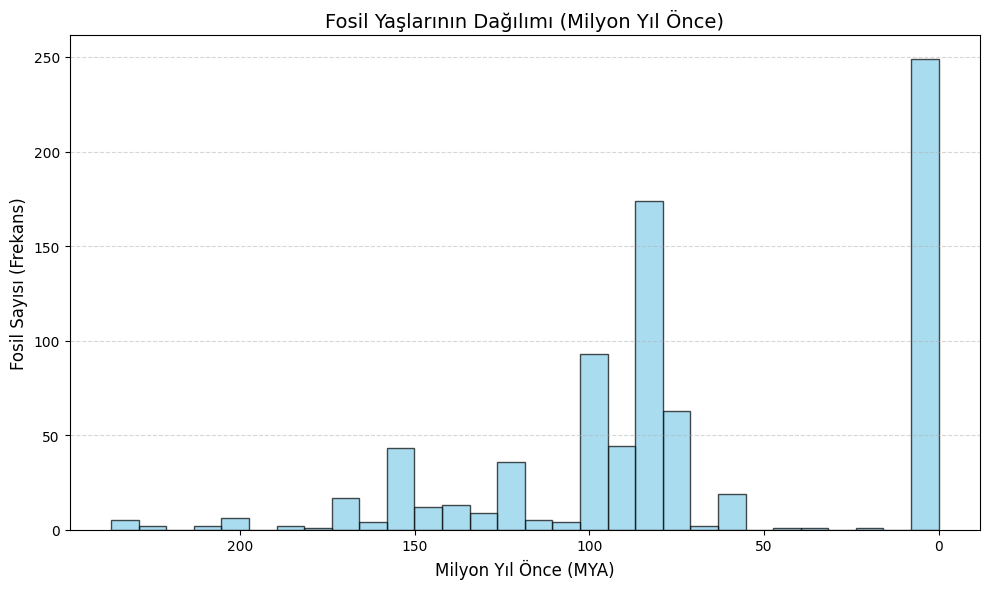

✅ Toplam 808 fosil yaş verisi analiz edildi.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- DOSYA BULUCU (Kırmızı Hata Giderici) ---
dosya_adi = 'dinozor_verisi_tam_database.csv'
dosya_yolu = ""
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file == dosya_adi:
            dosya_yolu = os.path.join(root, file)
            break
if dosya_yolu == "" and os.path.exists(dosya_adi): dosya_yolu = dosya_adi

# --- ANALİZ VE HİSTOGRAM ---
if dosya_yolu:
    df = pd.read_csv(dosya_yolu)
    
    # Yaş sütununu sayıya çevir ve boş olanları temizle
    df['early_age_mya'] = pd.to_numeric(df['early_age_mya'], errors='coerce')
    df_clean = df.dropna(subset=['early_age_mya'])

    # Grafik oluşturma
    plt.figure(figsize=(10, 6))
    
    # Histogram Çizimi
    # bins=30 veriyi 30 parçaya böler, color ile renk verdik
    plt.hist(df_clean["early_age_mya"], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    
    plt.title("Fosil Yaşlarının Dağılımı (Milyon Yıl Önce)", fontsize=14)
    plt.xlabel("Milyon Yıl Önce (MYA)", fontsize=12)
    plt.ylabel("Fosil Sayısı (Frekans)", fontsize=12)
    
    # X eksenini ters çevirelim (Jeolojik zamanlarda sağ taraf günümüzdür, sol taraf eskidir)
    plt.gca().invert_xaxis() 
    
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    print(f"✅ Toplam {len(df_clean)} fosil yaş verisi analiz edildi.")
else:
    print("❌ Dosya bulunamadı! Lütfen dosya adını kontrol edin.")

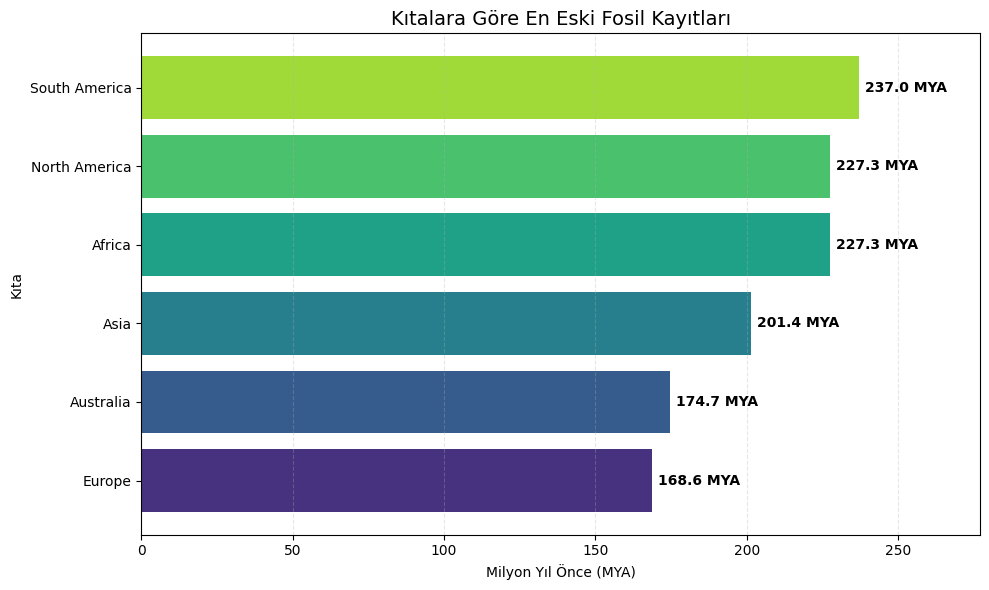

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- DOSYA BULUCU ---
dosya_adi = 'dinozor_verisi_tam_database.csv'
dosya_yolu = ""
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file == dosya_adi:
            dosya_yolu = os.path.join(root, file)
            break
if dosya_yolu == "" and os.path.exists(dosya_adi): dosya_yolu = dosya_adi

# --- ANALİZ VE ÇUBUK GRAFİĞİ ---
if dosya_yolu:
    df = pd.read_csv(dosya_yolu)
    df['early_age_mya'] = pd.to_numeric(df['early_age_mya'], errors='coerce')
    df_clean = df.dropna(subset=['early_age_mya', 'continent'])

    # Kıtalara göre en eski (maksimum) yaşları al
    kitalar_max_yas = df_clean.groupby("continent")["early_age_mya"].max().sort_values(ascending=True)

    # Grafik Çizimi
    plt.figure(figsize=(10, 6))
    
    # Yatay bar grafiği (hbar) karşılaştırma için mükemmeldir
    colors = sns.color_palette("viridis", len(kitalar_max_yas))
    bars = plt.barh(kitalar_max_yas.index, kitalar_max_yas.values, color=colors)

    # Değerleri çubukların üzerine yazalım
    for bar in bars:
        plt.text(bar.get_width() + 2, bar.get_y() + bar.get_height()/2, 
                 f'{bar.get_width():.1f} MYA', va='center', fontweight='bold')

    plt.title('Kıtalara Göre En Eski Fosil Kayıtları', fontsize=14)
    plt.xlabel('Milyon Yıl Önce (MYA)')
    plt.ylabel('Kıta')
    plt.xlim(0, max(kitalar_max_yas.values) + 40) # Sağda yazı için boşluk bırak
    plt.grid(axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("❌ Dosya bulunamadı!")

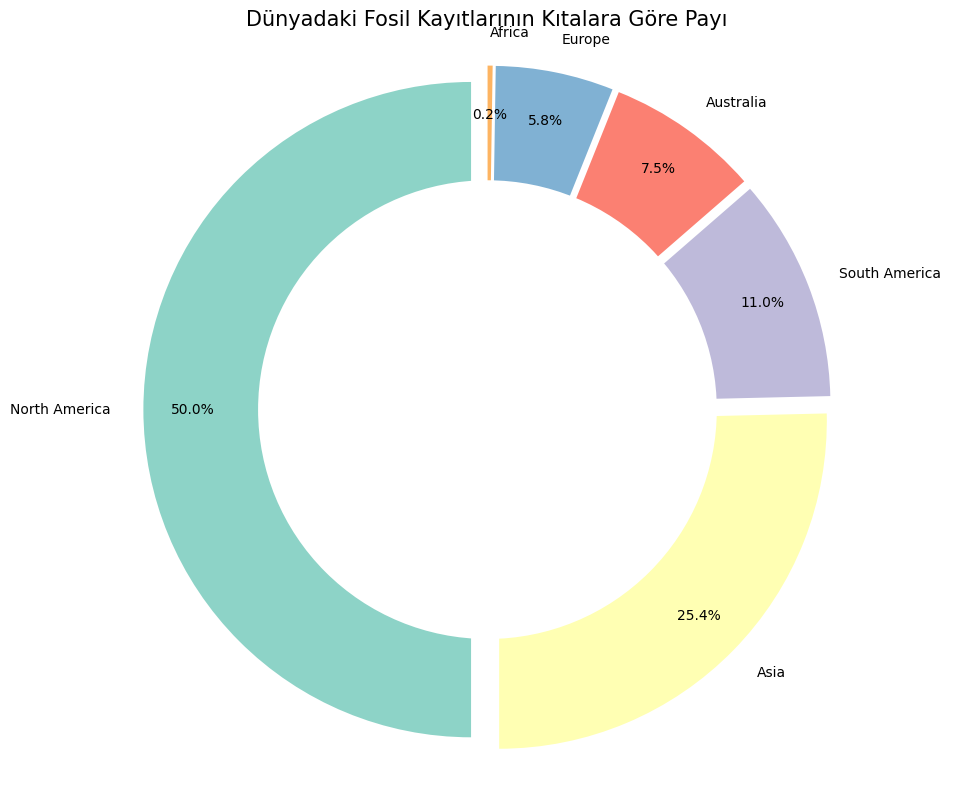

📌 Kıta Bazlı Fosil Sayıları:
continent
North America    404
Asia             205
South America     89
Australia         61
Europe            47
Africa             2
Name: count, dtype: int64


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# --- DOSYA BULUCU (Kırmızı Hata Giderici) ---
dosya_adi = 'dinozor_verisi_tam_database.csv'
dosya_yolu = ""
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file == dosya_adi:
            dosya_yolu = os.path.join(root, file)
            break
if dosya_yolu == "" and os.path.exists(dosya_adi): dosya_yolu = dosya_adi

# --- ANALİZ VE PASTA GRAFİĞİ ---
if dosya_yolu:
    df = pd.read_csv(dosya_yolu)
    
    # Kıta bazlı fosil sayılarını hesaplayalım
    kıta_sayilari = df['continent'].value_counts()

    # Grafik Çizimi
    plt.figure(figsize=(10, 8))
    
    # Renk paleti (Canlı renkler)
    renkler = plt.cm.Set3(range(len(kıta_sayilari)))

    # Pasta grafiğini oluşturma
    plt.pie(kıta_sayilari, 
            labels=kıta_sayilari.index, 
            autopct='%1.1f%%',       # Yüzdeleri göster
            startangle=90,           # Grafiği 90 dereceden başlat
            colors=renkler,          # Renk paletini uygula
            pctdistance=0.85,        # Yüzdeleri biraz merkeze çek
            explode=[0.05] * len(kıta_sayilari)) # Dilimleri hafifçe ayır

    # Ortasını boşaltıp "Simit" (Donut) görünümü verelim
    daire = plt.Circle((0,0), 0.70, fc='white')
    plt.gca().add_artist(daire)

    plt.title('Dünyadaki Fosil Kayıtlarının Kıtalara Göre Payı', fontsize=15)
    plt.axis('equal') # Tam yuvarlak olmasını sağlar
    plt.tight_layout()
    plt.show()

    # Ek Bilgi Yazdıralım
    print("📌 Kıta Bazlı Fosil Sayıları:")
    print(kıta_sayilari)

else:
    print("❌ Dosya bulunamadı!")